# HSA_Cam_B_008
## Define the full factorial design

In [1]:
import jax.numpy as jnp
import jax
import numpy as np
import matplotlib.pyplot as plt

import pymc as pm
import pytensor

import arviz as az
from scipy.optimize import minimize

pytensor.config.mode = "JAX"

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`
WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


In [2]:
from HSA_Cam_B_004 import (
    SIDX,
    TRUE_PARAMS,
    _kinetics_model,
    input_p,
    bmodel,
)

In [3]:
def post_model_over_T(proposal, idata, key="posterior"):

    test_params = {
        "p_i": input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        "T": jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        "k0": idata[key]["k0"].values.reshape(1, -1),
        "Ea_k": idata[key]["Ea_k"].values.reshape(1, -1),
        "A_oh": idata[key]["A_oh"].values.reshape(1, -1),
        "dH_oh": idata[key]["dH_oh"].values.reshape(1, -1),
        "A_h2": idata[key]["A_h2"].values.reshape(1, -1),
        "dH_h2": idata[key]["dH_h2"].values.reshape(1, -1),
        "A_mix": idata[key]["A_mix"].values.reshape(1, -1),
        "dH_mix": idata[key]["dH_mix"].values.reshape(1, -1),
    }

    test_res = _kinetics_model(**test_params)
    return test_res


def true_model_over_T(proposal):
    true_res_T = _kinetics_model(
        input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        *TRUE_PARAMS.values(),
    )
    return true_res_T

In [4]:
def plot_post_model_at_proposal(proposal, test_res, true_res, Ts):
    plt.plot(
        Ts,
        test_res.mean(axis=1),
    )
    plt.plot(
        Ts,
        true_res.squeeze(),
        color="black",
        linestyle="--",
    )
    plt.fill_between(
        x=Ts,
        y1=np.percentile(test_res, 2.5, axis=1),
        y2=np.percentile(test_res, 97.5, axis=1),
        alpha=0.3,
        zorder=0,
    )
    ax = plt.gca()
    ax.text(
        0.05,
        0.95,
        f"pred. @ p={proposal[1]:.2f}, F= {proposal[2]:.2f}, C= {proposal[3]:.2f}, H2= {proposal[4]:.2f}",
        transform=ax.transAxes,
        fontsize=10,
    )
    ax2 = ax.twinx()
    ax2.plot(
        Ts,
        np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
        color="orange",
    )

In [5]:
def observe_at_proposal(proposals):
    T = jnp.array([proposals[:, 0]], dtype=jnp.float32).reshape(-1, 1)
    p = jnp.array([proposals[:, 1]], dtype=jnp.float32).reshape(-1, 1)
    c2h = jnp.array([proposals[:, 2]], dtype=jnp.float32).reshape(-1, 1)
    f = jnp.array([proposals[:, 3]], dtype=jnp.float32).reshape(-1, 1)
    c2i = jnp.array([proposals[:, 4]], dtype=jnp.float32).reshape(-1, 1)

    p_i = input_p(p, c2h, f, c2i)

    r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
    r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
    return T, p, c2h, f, c2i, r_obs

In [6]:
def max_func(x, idata, key="posterior"):
    T = x[0].reshape(1, 1)
    p = x[1].reshape(1, 1)
    c2h = x[2].reshape(1, 1)
    f = x[3].reshape(1, 1)
    c2i = x[4].reshape(1, 1)
    p_i = input_p(p, c2h, f, c2i)
    res = _kinetics_model(
        p_i,
        T,
        idata[key]["k0"].values.reshape(1, -1),
        idata[key]["Ea_k"].values.reshape(1, -1),
        idata[key]["A_oh"].values.reshape(1, -1),
        idata[key]["dH_oh"].values.reshape(1, -1),
        idata[key]["A_h2"].values.reshape(1, -1),
        idata[key]["dH_h2"].values.reshape(1, -1),
        idata[key]["A_mix"].values.reshape(1, -1),
        idata[key]["dH_mix"].values.reshape(1, -1),
    )
    HDI = jnp.percentile(res, 97.5) - jnp.percentile(res, 2.5)
    return -HDI

## generate the default full factorial design

In [7]:
T_range = np.array([500, 600])
p_range = np.array([2, 20])
c2h_range = np.array([0.5, 2])
f_range = np.array([1, 1000])
c2i_range = np.array([0.1, 1])

Tgrid, pgrid, c2hgrid, fgrid, c2igrid = np.meshgrid(
    T_range, p_range, c2h_range, f_range, c2i_range
)

proposals = jnp.vstack(
    [Tgrid.ravel(), pgrid.ravel(), c2hgrid.ravel(), fgrid.ravel(), c2igrid.ravel()]
).T
proposals.shape  # Should be (32, 5) for a full factorial design with
print(proposals)

[[5.e+02 2.e+00 5.e-01 1.e+00 1.e-01]
 [5.e+02 2.e+00 5.e-01 1.e+00 1.e+00]
 [5.e+02 2.e+00 5.e-01 1.e+03 1.e-01]
 [5.e+02 2.e+00 5.e-01 1.e+03 1.e+00]
 [5.e+02 2.e+00 2.e+00 1.e+00 1.e-01]
 [5.e+02 2.e+00 2.e+00 1.e+00 1.e+00]
 [5.e+02 2.e+00 2.e+00 1.e+03 1.e-01]
 [5.e+02 2.e+00 2.e+00 1.e+03 1.e+00]
 [6.e+02 2.e+00 5.e-01 1.e+00 1.e-01]
 [6.e+02 2.e+00 5.e-01 1.e+00 1.e+00]
 [6.e+02 2.e+00 5.e-01 1.e+03 1.e-01]
 [6.e+02 2.e+00 5.e-01 1.e+03 1.e+00]
 [6.e+02 2.e+00 2.e+00 1.e+00 1.e-01]
 [6.e+02 2.e+00 2.e+00 1.e+00 1.e+00]
 [6.e+02 2.e+00 2.e+00 1.e+03 1.e-01]
 [6.e+02 2.e+00 2.e+00 1.e+03 1.e+00]
 [5.e+02 2.e+01 5.e-01 1.e+00 1.e-01]
 [5.e+02 2.e+01 5.e-01 1.e+00 1.e+00]
 [5.e+02 2.e+01 5.e-01 1.e+03 1.e-01]
 [5.e+02 2.e+01 5.e-01 1.e+03 1.e+00]
 [5.e+02 2.e+01 2.e+00 1.e+00 1.e-01]
 [5.e+02 2.e+01 2.e+00 1.e+00 1.e+00]
 [5.e+02 2.e+01 2.e+00 1.e+03 1.e-01]
 [5.e+02 2.e+01 2.e+00 1.e+03 1.e+00]
 [6.e+02 2.e+01 5.e-01 1.e+00 1.e-01]
 [6.e+02 2.e+01 5.e-01 1.e+00 1.e+00]
 [6.e+02 2.e

In [8]:
proposals_new = proposals[
    [
        2,
        10,
        18,
        26,
        6,
        14,
        22,
        30,
        3,
        11,
        19,
        27,
        1,
        9,
        17,
        25,
        0,
        8,
        16,
        24,
        4,
        12,
        20,
        28,
        5,
        13,
        21,
        29,
        7,
        15,
        23,
        31,
    ],  # Reduced set for quicker testing,
    :,
]
print(proposals_new)
print(proposals_new.shape)  # Should be (28, 5)

[[5.e+02 2.e+00 5.e-01 1.e+03 1.e-01]
 [6.e+02 2.e+00 5.e-01 1.e+03 1.e-01]
 [5.e+02 2.e+01 5.e-01 1.e+03 1.e-01]
 [6.e+02 2.e+01 5.e-01 1.e+03 1.e-01]
 [5.e+02 2.e+00 2.e+00 1.e+03 1.e-01]
 [6.e+02 2.e+00 2.e+00 1.e+03 1.e-01]
 [5.e+02 2.e+01 2.e+00 1.e+03 1.e-01]
 [6.e+02 2.e+01 2.e+00 1.e+03 1.e-01]
 [5.e+02 2.e+00 5.e-01 1.e+03 1.e+00]
 [6.e+02 2.e+00 5.e-01 1.e+03 1.e+00]
 [5.e+02 2.e+01 5.e-01 1.e+03 1.e+00]
 [6.e+02 2.e+01 5.e-01 1.e+03 1.e+00]
 [5.e+02 2.e+00 5.e-01 1.e+00 1.e+00]
 [6.e+02 2.e+00 5.e-01 1.e+00 1.e+00]
 [5.e+02 2.e+01 5.e-01 1.e+00 1.e+00]
 [6.e+02 2.e+01 5.e-01 1.e+00 1.e+00]
 [5.e+02 2.e+00 5.e-01 1.e+00 1.e-01]
 [6.e+02 2.e+00 5.e-01 1.e+00 1.e-01]
 [5.e+02 2.e+01 5.e-01 1.e+00 1.e-01]
 [6.e+02 2.e+01 5.e-01 1.e+00 1.e-01]
 [5.e+02 2.e+00 2.e+00 1.e+00 1.e-01]
 [6.e+02 2.e+00 2.e+00 1.e+00 1.e-01]
 [5.e+02 2.e+01 2.e+00 1.e+00 1.e-01]
 [6.e+02 2.e+01 2.e+00 1.e+00 1.e-01]
 [5.e+02 2.e+00 2.e+00 1.e+00 1.e+00]
 [6.e+02 2.e+00 2.e+00 1.e+00 1.e+00]
 [5.e+02 2.e

In [9]:
n_iterations = proposals.shape[0] // 2  # 16 iterations for quicker testing
# n_iterations = 2  # For quick testing
i_datas = []
max_HDIs = []
for i in range(n_iterations):
    print(f"Iteration {i+1}/{n_iterations}")
    T, p, c2h, f, c2i, r_obs = observe_at_proposal(proposals_new[0 : 2 * i, :])
    model = bmodel(
        (
            np.asarray(T),
            np.asarray(p),
            np.asarray(c2h),
            np.asarray(f),
            np.asarray(c2i),
        ),
        np.asarray(r_obs),
    )
    with model:
        idata = pm.sample(
            tune=1000,
            draws=4000,
            chains=4,
            target_accept=0.9,
            return_inferencedata=True,
        )
        i_datas.append(idata)
    sol = minimize(
        max_func,
        jnp.array([555.0, 15.0, 1.0, 1000.0, 0.5]),
        args=(idata, "posterior"),
        bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
        method="Nelder-Mead",
    )
    max_HDIs.append(-sol.fun)
    # proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)
    print("Next Proposal:\n", sol.x)

Iteration 1/16


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 35 seconds.


Next Proposal:
 [6.00000000e+02 2.00000000e+01 6.55927625e-01 9.99999975e+02
 1.00000000e+00]
Iteration 2/16


...

Next Proposal:
 [5.75194899e+02 2.00000000e+01 5.00000000e-01 1.00000000e+03
 1.00000000e+00]
Iteration 16/16


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 227 seconds.
There were 12 divergences after tuning. Increase `target_accept` or reparameterize.


Next Proposal:
 [5.71903100e+02 2.00000000e+01 5.00000000e-01 1.00000000e+03
 9.99999999e-01]


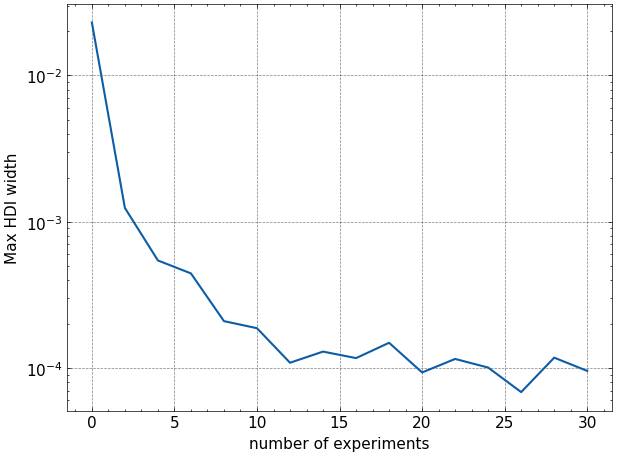

In [14]:
plt.plot(2 * np.arange(len(max_HDIs)), max_HDIs)
plt.xlabel("number of experiments")
plt.ylabel("Max HDI width")
plt.yscale("log")
plt.show()

In [20]:
for i, idata in enumerate(i_datas):
    if i == 0:
        idata.prior = prior_idata.prior
    else:
        idata.prior = i_datas[i - 1].posterior

NameError: name 'prior_idata' is not defined

C:\Users\hanne\AppData\Local\Temp\ipykernel_31384\2623506655.py:83: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


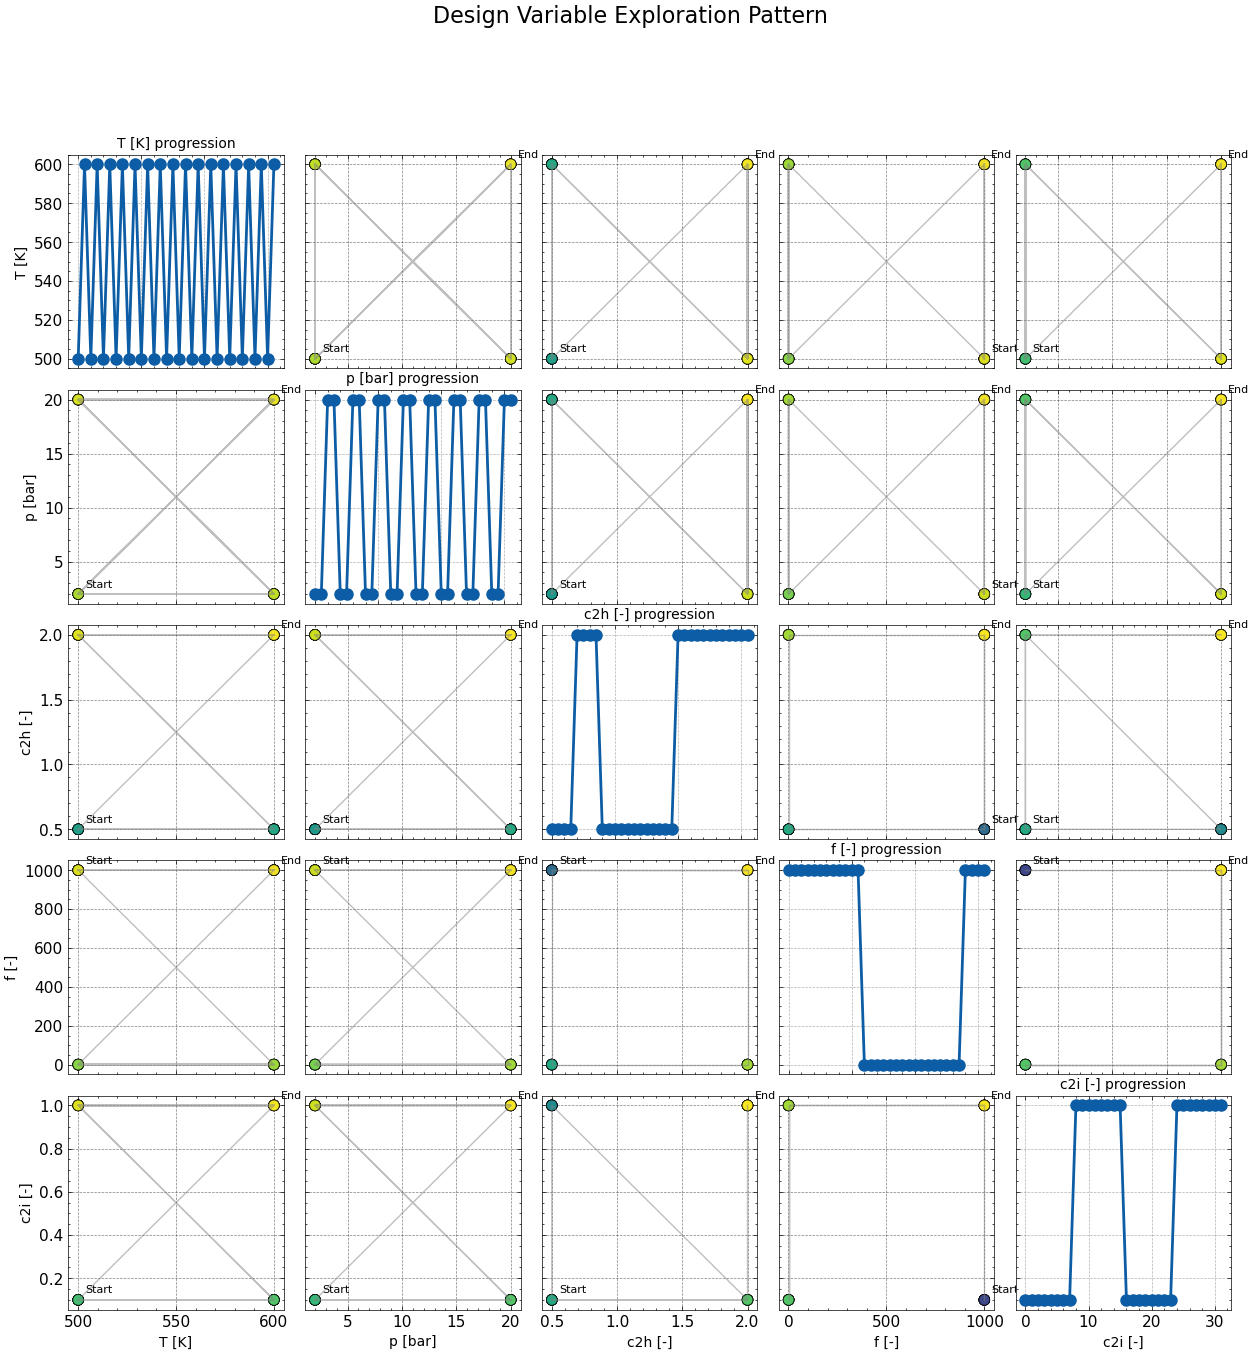

In [15]:
# create a 5x5 matrix plot with no gaps between the subplots
fig, axs = plt.subplots(
    5,
    5,
    figsize=(15, 15),
    sharex=False,
    sharey=False,
    gridspec_kw={"hspace": 0.1, "wspace": 0.1},
)

# Variable names for labeling
var_names = ["T [K]", "p [bar]", "c2h [-]", "f [-]", "c2i [-]"]

# Assuming proposals_new array exists with shape (n_experiments, 5)
n_experiments = proposals_new.shape[0]
experiment_order = np.arange(n_experiments)

for i in range(5):
    for j in range(5):
        ax = axs[i, j]

        if i == j:  # Diagonal: time series of each variable
            ax.plot(
                experiment_order, proposals_new[:, i], "o-", linewidth=2, markersize=8
            )
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
            ax.grid(True, alpha=0.3)
            if i == 4:  # Bottom row
                ax.set_xlabel("Experiment #")
        else:  # Off-diagonal: scatter plots
            # Color points by experiment order for temporal information
            scatter = ax.scatter(
                proposals_new[:, j],
                proposals_new[:, i],
                c=experiment_order,
                cmap="viridis",
                s=60,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )

            # Add trajectory lines
            ax.plot(
                proposals_new[:, j],
                proposals_new[:, i],
                "-",
                alpha=0.5,
                color="gray",
                linewidth=1,
            )

            # Label first and last points
            ax.annotate(
                "Start",
                (proposals_new[0, j], proposals_new[0, i]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8,
            )
            if n_experiments > 1:
                ax.annotate(
                    "End",
                    (proposals_new[-1, j], proposals_new[-1, i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                )

        # Set labels only on edges
        if i == 4:  # Bottom row
            ax.set_xlabel(var_names[j], fontsize=10)
        if j == 0:  # Left column
            ax.set_ylabel(var_names[i], fontsize=10)

        # Remove tick labels for inner plots
        if i < 4:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.suptitle("Design Variable Exploration Pattern", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

array([[<Axes: title={'center': 'dH_h2'}>,
        <Axes: title={'center': 'dH_h2'}>],
       [<Axes: title={'center': 'dH_mix'}>,
        <Axes: title={'center': 'dH_mix'}>],
       [<Axes: title={'center': 'k0'}>, <Axes: title={'center': 'k0'}>],
       [<Axes: title={'center': 'Ea_k'}>,
        <Axes: title={'center': 'Ea_k'}>],
       [<Axes: title={'center': 'A_oh'}>,
        <Axes: title={'center': 'A_oh'}>],
       [<Axes: title={'center': 'dH_oh'}>,
        <Axes: title={'center': 'dH_oh'}>],
       [<Axes: title={'center': 'A_h2'}>,
        <Axes: title={'center': 'A_h2'}>],
       [<Axes: title={'center': 'A_mix'}>,
        <Axes: title={'center': 'A_mix'}>],
       [<Axes: title={'center': 'sigma_r'}>,
        <Axes: title={'center': 'sigma_r'}>],
       [<Axes: title={'center': 'y_hat'}>,
        <Axes: title={'center': 'y_hat'}>]], dtype=object)

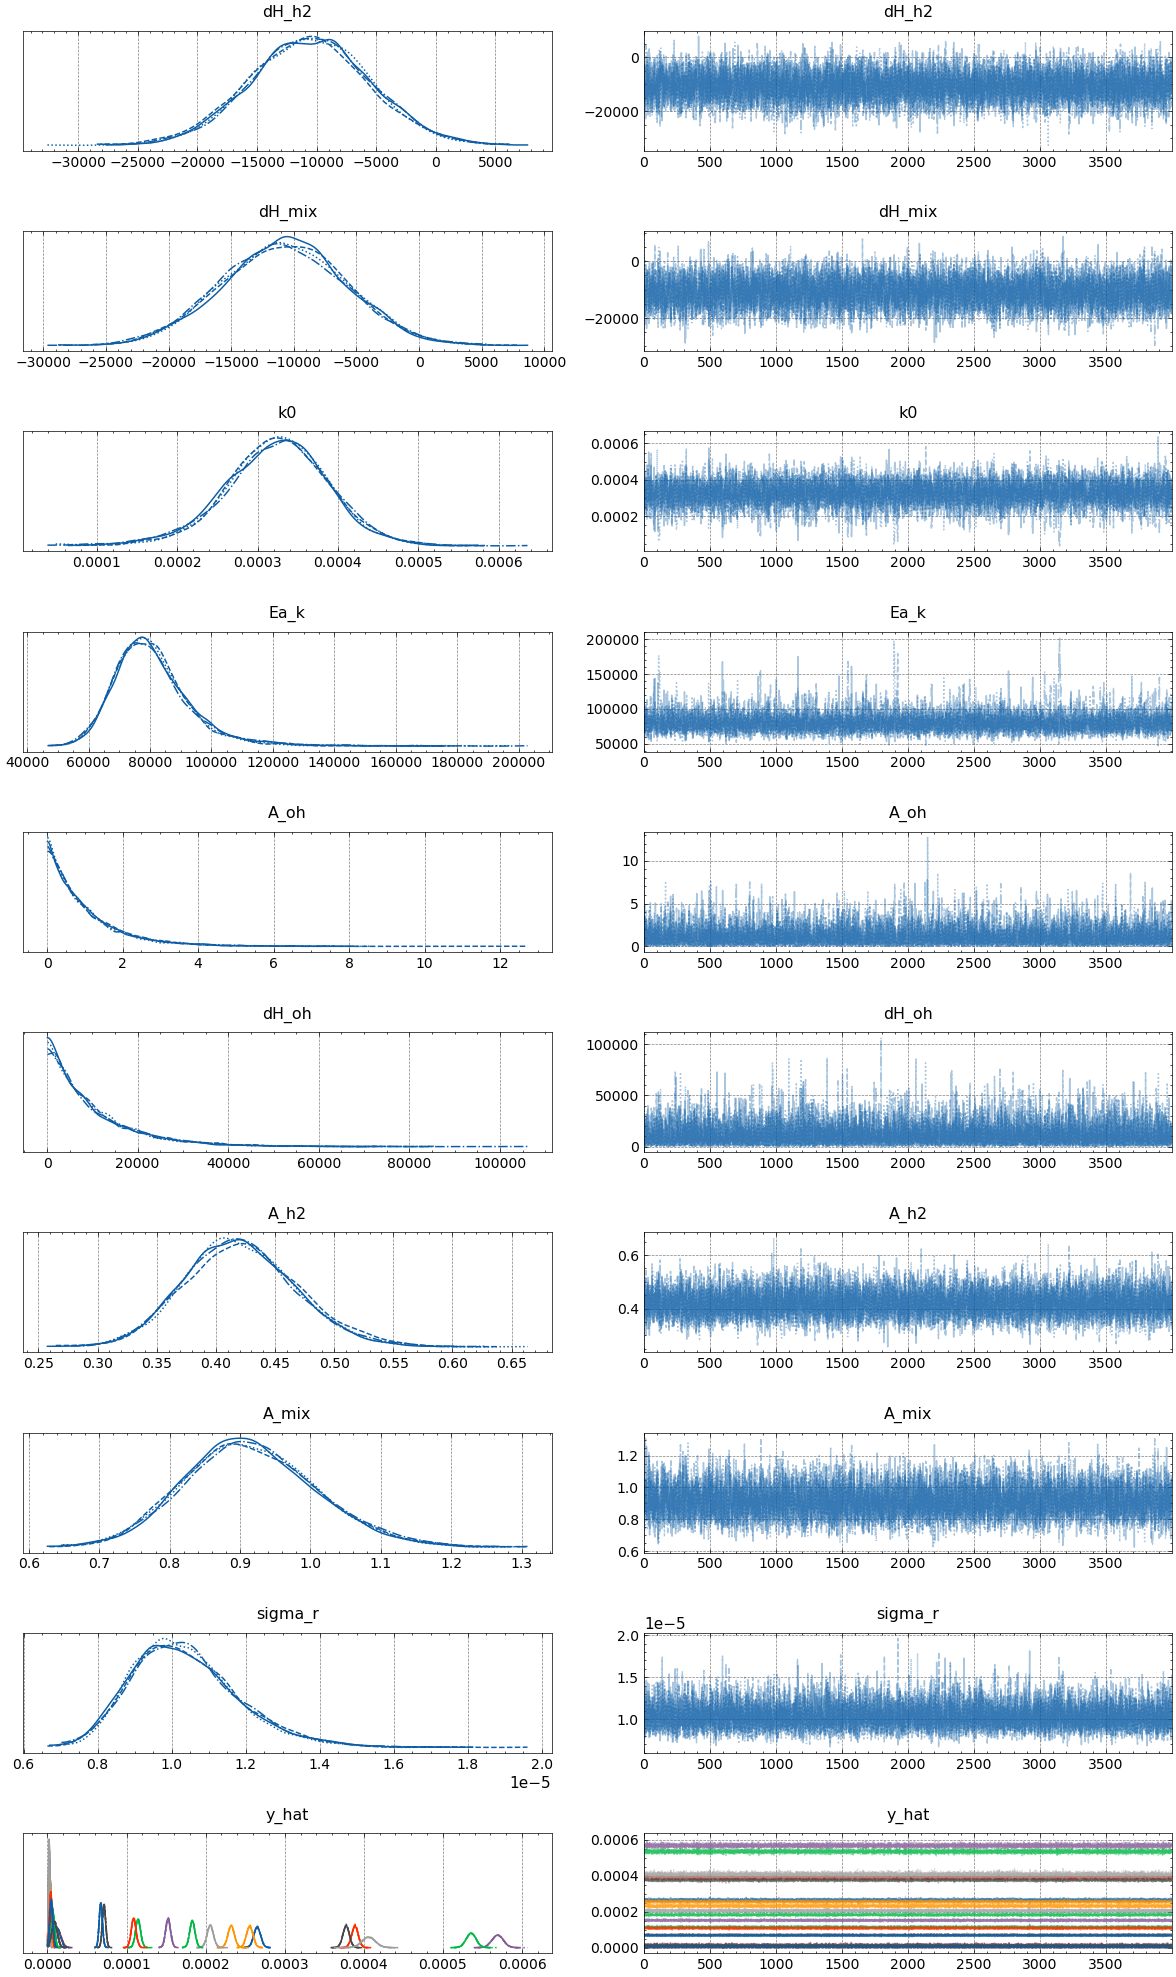

In [16]:
az.plot_trace(i_datas[-1], divergences=False)

In [17]:
pm.summary(i_datas[-1])

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
dH_h2,-10596.458,5018.751,-19800.878,-951.977,54.028,40.182,8628.0,9724.0,1.0
dH_mix,-10781.083,4940.357,-20040.791,-1594.747,59.252,38.312,6959.0,8994.0,1.0
k0,0.000,0.000,0.000,0.000,0.000,0.000,5789.0,4365.0,1.0
Ea_k,80866.005,13403.179,58388.160,104343.898,211.574,432.647,5955.0,4284.0,1.0
A_oh,0.996,1.020,0.000,2.826,0.009,0.014,7448.0,4914.0,1.0
dH_oh,10100.694,10233.026,2.743,28772.478,83.157,135.475,9055.0,5978.0,1.0
A_h2,0.421,0.047,0.333,0.510,0.001,0.000,8449.0,9455.0,1.0
A_mix,0.915,0.093,0.747,1.096,0.001,0.001,6949.0,8407.0,1.0
sigma_r,0.000,0.000,0.000,0.000,0.000,0.000,10023.0,9756.0,1.0
"y_hat[0, 0]",0.000,0.000,0.000,0.000,0.000,0.000,6713.0,4289.0,1.0


In [23]:
import xarray
from HSA_Cam_B_004 import kl_divergence_between_models

info_gains = []
for i in range(1, 16):
    klds = kl_divergence_between_models(
        idata_new=i_datas[i],
        idata_old=i_datas[i - 1] if i > 0 else i_datas[0],
        key_new="posterior",
        key_old="posterior" if i > 0 else "prior",
        n_samples=5,
        var_names=[
            "k0",
            "Ea_k",
            "A_oh",
            "dH_oh",
            "A_h2",
            "dH_h2",
            "A_mix",
            "dH_mix",
        ],
    )
    info_gains.append(klds)
kldses = []
for i, klds in enumerate(info_gains):
    print(klds)
    print(klds.sum())
    kldses.append(klds.sum())

[ 0.75910598  0.9987178  -0.05167954  0.40456648  0.37788709  0.52083753
  0.59322651  0.43309006]
4.035751907119309
[ 1.18783219  0.53613131 -0.09871002 -0.06972487  0.15002433  0.09490106
  0.91531607  0.07880707]
2.794577127393277
[1.07554351 0.45743711 0.22910673 0.0399731  0.83019084 0.06441656
 0.9500693  0.73230766]
4.379044816144485
[ 2.18949752  0.93731181  1.0421548   0.10949729  0.15271961 -0.0305195
  0.63206577  0.1305578 ]
5.163285085244292
[ 0.63329453  0.31590219 -0.08403963  0.3618045   0.09735925 -0.06678011
  0.22650248  0.02747704]
1.5115202464900885
[ 2.38587593  1.52496651 -0.18792172  2.06655005  0.30338873  0.29731342
  0.27804574  0.84618311]
7.514401784330862
[ 0.56422225  0.52394088  0.83047379  1.59568821  2.07991661  0.79073512
  0.03601531 -0.03100428]
6.389987896762918
[ 0.34226294  0.02918862  0.12721748 -0.15377896  0.02873363  0.14839168
  3.46789819 -0.11061832]
3.8792952620339833
[ 0.41063805  0.40929544 -0.0262609  -0.07432003 -0.12043034  0.5213092

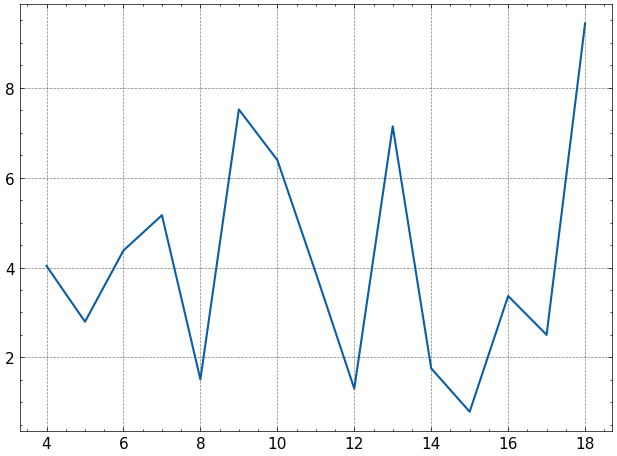

In [24]:
plt.plot(np.arange(len(kldses)) + 4, kldses)